# Black hole occupation fraction over redshift

The black hole occupation fraction (BHOF) is the fraction of *galaxies* holding
at least one black hole. This notebook measures it across all 33 snapshots of
`SM5_DFD_3_TNG`, using the catalogue written by
[`py_files/wandering_bh_catalog.py`](../py_files/wandering_bh_catalog.py), in
three flavours:

| flavour | a galaxy counts as occupied when it holds at least one |
|---|---|
| **total** | black hole of any kind |
| **central** | black hole inside its stellar half-mass radius |
| **wandering** | black hole outside its stellar half-mass radius |

## The catalogue supplies the numerator, not the denominator

`wandering_bh_SM5_DFD_3_TNG.hdf5` stores only subhalos that **host at least one
black hole and have stars**, which is exactly the numerator of an occupation
fraction. The denominator, every resolved galaxy *including the ones holding no
black hole at all*, is not in the file: `/snapshot/n_subhalos` is a bare total
with no stellar masses attached. So the galaxy sample is read once from the
postprocessed group catalogues and cached next to the catalogue.

## What counts as a galaxy

A galaxy is a subhalo resolved by at least `MIN_STAR_PARTICLES = 10` star
particles. Below roughly five star particles SUBFIND reports a zero stellar
half-mass radius, which would label every black hole a wanderer by
construction, so this floor is a resolution requirement rather than a cosmetic
cut. It is the same cut used in `plotly_interactive_wanderers.ipynb`, so these
numbers are comparable to that notebook.

In [1]:
%matplotlib inline

import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import h5py

from cosmo_sim_tools import brahma

# Shared figure styling (fonts, ticks, legend) lives in py_files/plot_style.py
sys.path.append('../py_files/')
import plot_style as ps

ps.set_style('paper', font_scale=1.15)

SIM_NAME = 'SM5_DFD_3_TNG'
SIM_FILE = ('/orange/lblecha/aklantbhowmick/GAS_BASED_SEED_MODEL_UNIFORM_RUNS/'
            f'L12p5n512/AREPO/{SIM_NAME}/')
DATA_DIR = Path('/orange/lblecha/pranavsatheesh/wandering_bhs/Data')
CATALOGUE = DATA_DIR / f'wandering_bh_{SIM_NAME}.hdf5'
GALAXY_CACHE = DATA_DIR / f'galaxy_sample_{SIM_NAME}.npz'
FIGURE_DIR = Path('../figures')

MIN_STAR_PARTICLES = 10

## The galaxy sample

One pass over the 33 postprocessed group catalogues, kept in a small `.npz` so
the rest of the notebook runs instantly. Only subhalos with at least one star
particle are stored, which keeps the cache under a megabyte. The star-particle
count is kept so `MIN_STAR_PARTICLES` can be changed without a rebuild, and the
black hole count so the join against the catalogue can be checked.

In [2]:
def build_galaxy_cache(path=GALAXY_CACHE):
    """Stellar mass, star-particle and BH counts of every star-containing subhalo.

    This is the BHOF denominator. It takes about 20-40 s for all 33 snapshots,
    almost all of it opening group-catalogue chunks.
    """
    with h5py.File(CATALOGUE, 'r') as catalogue:
        hubble_param = float(catalogue.attrs['HubbleParam'])
        snapshots = catalogue['snapshot/snap'][:]
        redshifts = catalogue['snapshot/redshift'][:]

    columns = {}
    for snapshot in snapshots:
        subhalos = brahma.groupcat.loadSubhalos_postprocessed(
            SIM_FILE, int(snapshot), fields=['SubhaloLenType', 'SubhaloMassType'])
        length_by_type = np.asarray(subhalos['SubhaloLenType'])
        star_particles = length_by_type[:, 4]

        has_stars = np.flatnonzero(star_particles >= 1)
        columns[f'index_{snapshot}'] = has_stars.astype(np.int32)
        columns[f'star_particles_{snapshot}'] = star_particles[has_stars].astype(np.int32)
        columns[f'bh_particles_{snapshot}'] = length_by_type[has_stars, 5].astype(np.int32)
        columns[f'stellar_mass_{snapshot}'] = (
            np.asarray(subhalos['SubhaloMassType'])[has_stars, 4] * 1e10 / hubble_param
        ).astype(np.float32)

    np.savez_compressed(path, snap=snapshots, redshift=redshifts, **columns)
    return np.load(path)


galaxy_sample = np.load(GALAXY_CACHE) if GALAXY_CACHE.exists() else build_galaxy_cache()
catalogue = h5py.File(CATALOGUE, 'r')

snapshots = galaxy_sample['snap']
redshifts = galaxy_sample['redshift']
print(f'{len(snapshots)} snapshots, z = {redshifts.max():.2f} to {redshifts.min():.2f}')
print(f"{len(catalogue['bh/r_kpc']):,} black holes in "
      f"{len(catalogue['subhalo/index']):,} host-subhalo rows")

33 snapshots, z = 25.05 to 0.00
151,386 black holes in 54,657 host-subhalo rows


## Joining the catalogue onto the galaxy sample

The catalogue counts black holes per *host*; the occupation fraction needs a
count per *galaxy*, with an explicit zero for the galaxies the catalogue never
mentions. `/subhalo/index` is ascending within each snapshot (hosts are
collected with `np.flatnonzero`), so the join is a `searchsorted` per snapshot
and unmatched galaxies keep their zero.

`/subhalo/is_central` is deliberately *not* used here: it says whether the
subhalo is the primary of its FoF group, not whether its black hole sits at the
centre. The central black hole count is the host's total minus its wanderers.

In [3]:
host_snap = catalogue['subhalo/snap'][:]
host_index = catalogue['subhalo/index'][:]
host_bh_total = catalogue['subhalo/bh_count'][:].astype(np.int64)

# collapse the per-BH wandering flag onto its host row
host_bh_wandering = np.bincount(
    catalogue['bh/subhalo_row'][:][catalogue['bh/is_wandering'][:]],
    minlength=len(host_index)).astype(np.int64)


def occupation_table(min_star_particles=MIN_STAR_PARTICLES):
    """Per-galaxy black hole counts for every snapshot, as flat arrays.

    One row per galaxy per snapshot, so a later cut in redshift or stellar mass
    is just a mask. `n_bh_expected` is the group catalogue's own count for the
    same galaxy, carried through so the join can be verified.
    """
    columns = {name: [] for name in
               ['snap', 'redshift', 'log_stellar_mass',
                'n_bh_total', 'n_bh_wandering', 'n_bh_expected']}

    for snapshot, redshift in zip(snapshots, redshifts):
        star_particles = galaxy_sample[f'star_particles_{snapshot}']
        stellar_mass = galaxy_sample[f'stellar_mass_{snapshot}']
        subhalo_index = galaxy_sample[f'index_{snapshot}']
        bh_particles = galaxy_sample[f'bh_particles_{snapshot}']

        galaxies = (star_particles >= min_star_particles) & (stellar_mass > 0)
        if not galaxies.any():
            continue
        galaxy_index = subhalo_index[galaxies]
        n_galaxies = int(galaxies.sum())

        this_snap = host_snap == snapshot
        hosts_here = host_index[this_snap]
        assert np.all(np.diff(hosts_here) > 0), f'snap {snapshot}: /subhalo/index not ascending'
        rows_here = np.flatnonzero(this_snap)

        position = np.searchsorted(hosts_here, galaxy_index)
        matched = (position < len(hosts_here)) & (
            hosts_here[np.minimum(position, max(len(hosts_here) - 1, 0))] == galaxy_index)
        row = rows_here[position[matched]]

        total = np.zeros(n_galaxies, dtype=np.int64)
        wandering = np.zeros(n_galaxies, dtype=np.int64)
        total[matched] = host_bh_total[row]
        wandering[matched] = host_bh_wandering[row]

        columns['snap'].append(np.full(n_galaxies, snapshot, dtype=np.int16))
        columns['redshift'].append(np.full(n_galaxies, redshift, dtype=np.float32))
        columns['log_stellar_mass'].append(np.log10(stellar_mass[galaxies]))
        columns['n_bh_total'].append(total)
        columns['n_bh_wandering'].append(wandering)
        columns['n_bh_expected'].append(bh_particles[galaxies].astype(np.int64))

    return {name: np.concatenate(value) for name, value in columns.items()}


galaxies = occupation_table()
galaxies['n_bh_central'] = galaxies['n_bh_total'] - galaxies['n_bh_wandering']
OCCUPIED = {
    'total': galaxies['n_bh_total'] > 0,
    'central': galaxies['n_bh_central'] > 0,
    'wandering': galaxies['n_bh_wandering'] > 0,
}
print(f"{len(galaxies['snap']):,} galaxy-snapshot rows "
      f'(>= {MIN_STAR_PARTICLES} star particles)')

18,750 galaxy-snapshot rows (>= 10 star particles)


### Is the numerator complete?

The catalogue drops black hole hosts with no resolved stellar body, and at
z = 10 that is 14,537 hosts against 1,322 kept. Almost all of them sit below the
star-particle floor and so are absent from the denominator too, but that has to
be checked rather than assumed: a dropped host *above* the floor would bias the
BHOF downwards without any warning.

The group catalogue's own `SubhaloLenType[:, 5]` is the independent reference,
so the check is that it agrees galaxy by galaxy with what the catalogue
reports.

In [4]:
disagree = galaxies['n_bh_total'] != galaxies['n_bh_expected']
print(f'galaxies where the catalogue and the group catalogue disagree on the '
      f'BH count: {np.count_nonzero(disagree)} of {len(disagree):,}')

missing = disagree & (galaxies['n_bh_total'] == 0)
print(f'  of which the catalogue has no row at all: {np.count_nonzero(missing)}')
assert not disagree.any(), 'the join lost or mismatched black holes'

# the complement: how much of the galaxy sample holds no black hole at all
for redshift_target in [10, 5, 2, 0]:
    nearest = int(np.argmin(np.abs(redshifts - redshift_target)))
    rows = galaxies['snap'] == snapshots[nearest]
    if rows.sum() == 0:
        continue
    print(f'  z = {redshifts[nearest]:5.2f}: {rows.sum():5d} galaxies, '
          f"{np.count_nonzero(~OCCUPIED['total'][rows]):4d} with no black hole")

galaxies where the catalogue and the group catalogue disagree on the BH count: 0 of 18,750
  of which the catalogue has no row at all: 0
  z = 10.00:    67 galaxies,    0 with no black hole
  z =  5.00:   966 galaxies,    1 with no black hole
  z =  2.00:  1686 galaxies,    7 with no black hole
  z =  0.00:  1119 galaxies,   70 with no black hole


## BHOF against redshift

Error bars are 68% Wilson score intervals. The Wilson form matters here because
the total BHOF sits very close to 1, where the usual $\sqrt{p(1-p)/N}$ error
collapses to zero and would claim far more precision than 1,000-odd galaxies
support.

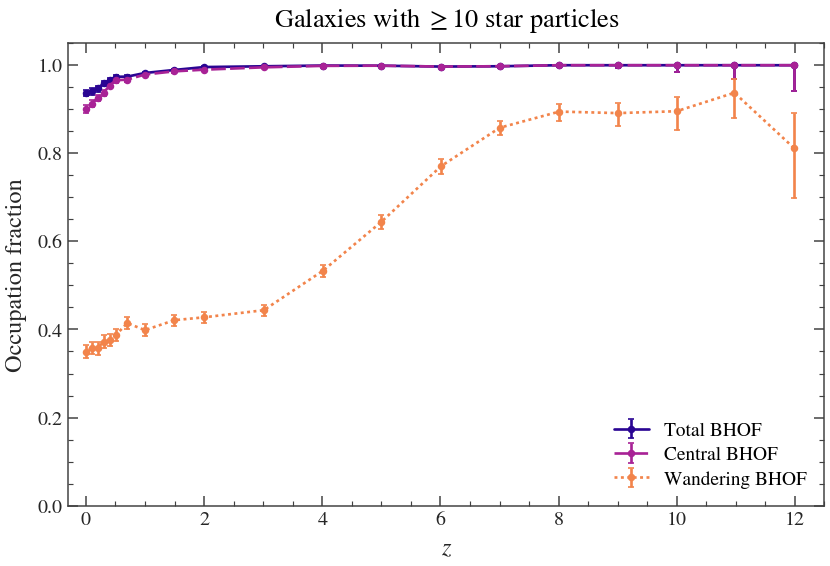

     z   N_gal   total  central  wandering
 11.98      16   1.000    1.000      0.812
 10.98      32   1.000    1.000      0.938
 10.00      67   1.000    1.000      0.896
  9.00     138   1.000    1.000      0.891
  8.01     247   1.000    1.000      0.895
  7.01     430   0.998    0.998      0.858
  6.01     659   0.997    0.997      0.771
  5.00     966   0.999    0.999      0.644
  4.01    1362   0.999    0.999      0.533
  3.01    1679   0.998    0.995      0.444
  2.00    1686   0.996    0.990      0.428
  1.50    1584   0.989    0.986      0.421
  1.00    1418   0.982    0.979      0.398
  0.70    1317   0.974    0.967      0.415
  0.50    1256   0.974    0.966      0.387
  0.40    1233   0.966    0.954      0.376
  0.30    1213   0.959    0.937      0.373
  0.20    1174   0.947    0.926      0.357
  0.10    1149   0.941    0.913      0.358
  0.00    1119   0.937    0.902      0.349


In [5]:
def wilson_interval(n_occupied, n_galaxies, z_score=1.0):
    """68% Wilson score interval for a binomial fraction.

    Stays inside [0, 1] and keeps a sensible width as the fraction approaches
    either end, unlike the normal approximation.
    """
    n_galaxies = np.maximum(n_galaxies, 1)
    fraction = n_occupied / n_galaxies
    denominator = 1 + z_score ** 2 / n_galaxies
    centre = (fraction + z_score ** 2 / (2 * n_galaxies)) / denominator
    half_width = (z_score / denominator) * np.sqrt(
        fraction * (1 - fraction) / n_galaxies + z_score ** 2 / (4 * n_galaxies ** 2))
    return np.clip(centre - half_width, 0.0, 1.0), np.clip(centre + half_width, 0.0, 1.0)


def bhof_vs_redshift(rows, min_galaxies=10):
    """BHOF per snapshot for the galaxies selected by the boolean mask `rows`."""
    out = {'redshift': [], 'n_galaxies': []}
    out.update({flavour: [] for flavour in OCCUPIED})
    out.update({f'{flavour}_error': [] for flavour in OCCUPIED})

    for snapshot, redshift in zip(snapshots, redshifts):
        selected = rows & (galaxies['snap'] == snapshot)
        n_galaxies = int(selected.sum())
        if n_galaxies < min_galaxies:
            continue
        out['redshift'].append(redshift)
        out['n_galaxies'].append(n_galaxies)
        for flavour, occupied in OCCUPIED.items():
            n_occupied = int(occupied[selected].sum())
            fraction = n_occupied / n_galaxies
            lower, upper = wilson_interval(n_occupied, n_galaxies)
            out[flavour].append(fraction)
            # a fraction of exactly 1 puts the Wilson upper edge on the
            # fraction itself, where rounding can leave it a hair below and
            # errorbar rejects the negative
            out[f'{flavour}_error'].append([max(fraction - lower, 0.0),
                                            max(upper - fraction, 0.0)])

    return {key: np.asarray(value).T if key.endswith('error') else np.asarray(value)
            for key, value in out.items()}


everything = bhof_vs_redshift(np.ones(len(galaxies['snap']), dtype=bool))

fig, ax = plt.subplots(figsize=(7.2, 5.0))
flavour_colors = ps.sequential_colors(3, cmap='plasma')
flavour_dashes = ps.line_styles(3)

for color, dash, flavour in zip(flavour_colors, flavour_dashes,
                                ['total', 'central', 'wandering']):
    ax.errorbar(everything['redshift'], everything[flavour],
                yerr=everything[f'{flavour}_error'],
                color=color, linestyle=dash, marker='o', markersize=3.5,
                capsize=2, label=f'{flavour.capitalize()} BHOF')

ax.set_xlabel(r'$z$')
ax.set_ylabel('Occupation fraction')
ax.set_ylim(0, 1.05)
ax.set_xlim(redshifts.min() - 0.3, 12.5)
ax.legend(frameon=False, loc='lower right')
ax.set_title(rf'Galaxies with $\geq {MIN_STAR_PARTICLES}$ star particles')
fig.tight_layout()
fig.savefig(FIGURE_DIR / f'bhof_vs_redshift_{SIM_NAME}.pdf')
plt.show()

print(f'{"z":>6} {"N_gal":>7} {"total":>7} {"central":>8} {"wandering":>10}')
for i, redshift in enumerate(everything['redshift']):
    print(f"{redshift:6.2f} {everything['n_galaxies'][i]:7d} "
          f"{everything['total'][i]:7.3f} {everything['central'][i]:8.3f} "
          f"{everything['wandering'][i]:10.3f}")

## Splitting the redshift trend by stellar mass

The curve above mixes two effects: genuine evolution at fixed mass, and the
shifting mass distribution of the galaxy sample as the box builds up more
massive galaxies. Binning in stellar mass separates them.

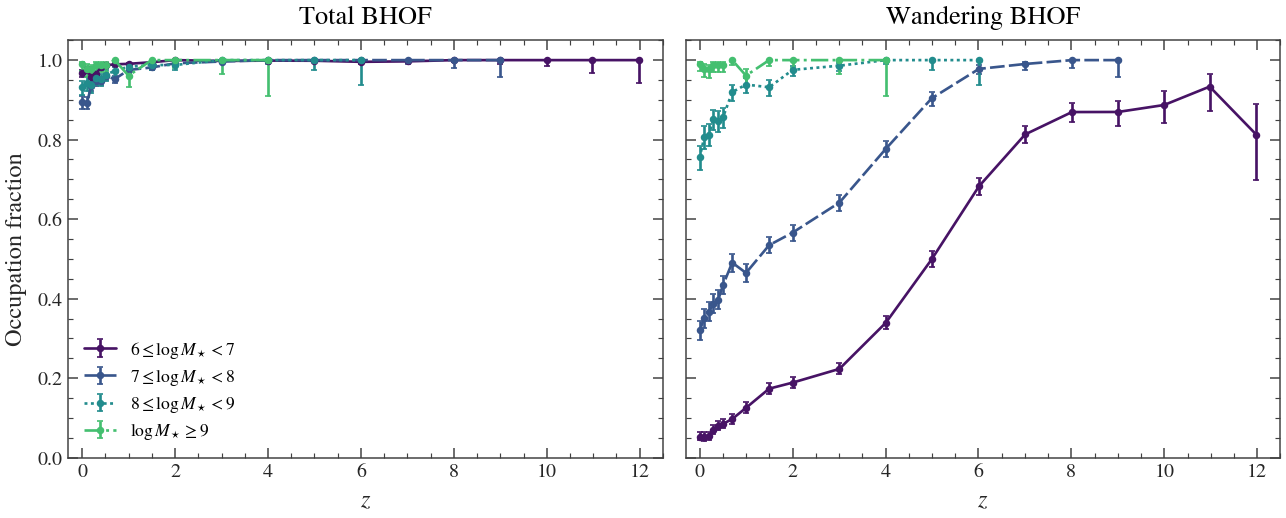

In [6]:
MASS_EDGES = np.array([6.0, 7.0, 8.0, 9.0, 12.0])

fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.6), sharex=True, sharey=True)
mass_colors = ps.sequential_colors(len(MASS_EDGES) - 1, cmap='viridis')
mass_dashes = ps.line_styles(len(MASS_EDGES) - 1)

for ax, flavour in zip(axes, ['total', 'wandering']):
    for color, dash, (low, high) in zip(mass_colors, mass_dashes,
                                        zip(MASS_EDGES[:-1], MASS_EDGES[1:])):
        in_bin = (galaxies['log_stellar_mass'] >= low) & (galaxies['log_stellar_mass'] < high)
        binned = bhof_vs_redshift(in_bin)
        if len(binned['redshift']) == 0:
            continue
        label = (rf'${low:.0f} \leq \log M_\star < {high:.0f}$' if high < 12
                 else rf'$\log M_\star \geq {low:.0f}$')
        ax.errorbar(binned['redshift'], binned[flavour], yerr=binned[f'{flavour}_error'],
                    color=color, linestyle=dash, marker='o', markersize=3.5,
                    capsize=2, label=label)
    ax.set_xlabel(r'$z$')
    ax.set_title(f'{flavour.capitalize()} BHOF')

axes[0].set_ylabel('Occupation fraction')
axes[0].set_ylim(0, 1.05)
axes[0].set_xlim(redshifts.min() - 0.3, 12.5)
axes[0].legend(frameon=False, loc='lower left', fontsize='small')
fig.tight_layout()
fig.savefig(FIGURE_DIR / f'bhof_vs_redshift_massbins_{SIM_NAME}.pdf')
plt.show()

## BHOF against stellar mass, in redshift slices

The complementary view, and the one directly comparable to
`plotly_interactive_wanderers.ipynb`. The curves are Gaussian-weighted means in
$\log M_\star$ rather than histograms, so they carry no bin-edge steps, and they
are blanked where the effective (Kish) sample size falls below
`MIN_EFFECTIVE_COUNT`, so each line stops where the box runs out of galaxies
instead of running on into noise.

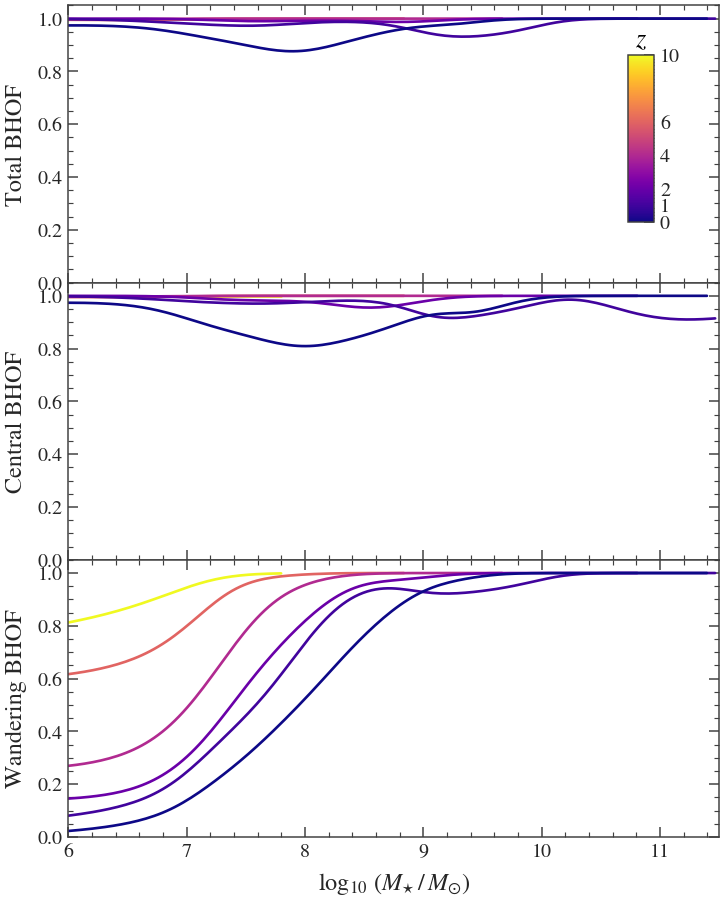

In [7]:
MASS_GRID = np.linspace(6.0, 11.5, 160)
BANDWIDTH = 0.3
MIN_EFFECTIVE_COUNT = 8
REDSHIFT_SLICES = [10, 6, 4, 2, 1, 0]


def smoothed_occupation_fraction(log_stellar_mass, occupied, mass_grid=MASS_GRID,
                                 bandwidth=BANDWIDTH,
                                 min_effective_count=MIN_EFFECTIVE_COUNT):
    """Occupation fraction on `mass_grid` as a Gaussian-weighted mean."""
    weights = np.exp(
        -0.5 * ((log_stellar_mass[:, None] - mass_grid[None, :]) / bandwidth) ** 2)
    total_weight = weights.sum(axis=0)
    effective_count = total_weight ** 2 / np.maximum((weights ** 2).sum(axis=0), 1e-300)
    fraction = (weights * occupied[:, None]).sum(axis=0) / np.maximum(total_weight, 1e-300)
    return np.where(effective_count >= min_effective_count, fraction, np.nan)


color_norm = Normalize(vmin=0, vmax=max(REDSHIFT_SLICES))
colormap = plt.get_cmap('plasma')

fig, axes = plt.subplots(3, 1, figsize=(7.0, 9.0), sharex=True)
for requested in REDSHIFT_SLICES:
    nearest = int(np.argmin(np.abs(redshifts - requested)))
    rows = galaxies['snap'] == snapshots[nearest]
    if rows.sum() < 10:
        continue
    color = colormap(color_norm(redshifts[nearest]))
    for ax, flavour in zip(axes, ['total', 'central', 'wandering']):
        ax.plot(MASS_GRID,
                smoothed_occupation_fraction(galaxies['log_stellar_mass'][rows],
                                             OCCUPIED[flavour][rows]),
                color=color)

for ax, flavour in zip(axes, ['total', 'central', 'wandering']):
    ax.set_ylabel(f'{flavour.capitalize()} BHOF')
    ax.set_ylim(0, 1.05)
    ax.set_yticks(np.arange(0, 1.01, 0.2))

axes[-1].set_xlim(6, 11.5)
axes[-1].set_xlabel(r'$\log_{10}\,(M_{\star}\,/\,M_{\odot})$')
fig.subplots_adjust(hspace=0)

colorbar_axes = axes[0].inset_axes([0.86, 0.22, 0.04, 0.60])
colorbar = fig.colorbar(ScalarMappable(norm=color_norm, cmap=colormap), cax=colorbar_axes)
colorbar.set_ticks(REDSHIFT_SLICES)
colorbar.ax.set_title(r'$z$', pad=5)

fig.savefig(FIGURE_DIR / f'bhof_vs_stellar_mass_{SIM_NAME}.pdf', bbox_inches='tight')
plt.show()

## Numbers behind the figures

In [8]:
header = (f'{"z":>6} {"logM* bin":>12} {"N_gal":>6} {"BHOF_tot":>9} '
          f'{"BHOF_wand":>10} {"<N_bh>":>8}')
print(header)
for requested in REDSHIFT_SLICES:
    nearest = int(np.argmin(np.abs(redshifts - requested)))
    rows = galaxies['snap'] == snapshots[nearest]
    if rows.sum() < 10:
        continue
    for low, high in zip(MASS_EDGES[:-1], MASS_EDGES[1:]):
        in_bin = (rows & (galaxies['log_stellar_mass'] >= low)
                  & (galaxies['log_stellar_mass'] < high))
        if in_bin.sum() < 5:
            continue
        print(f'{redshifts[nearest]:6.2f} {f"{low:.0f}-{high:.0f}":>12} {in_bin.sum():6d} '
              f'{OCCUPIED["total"][in_bin].mean():9.3f} '
              f'{OCCUPIED["wandering"][in_bin].mean():10.3f} '
              f'{galaxies["n_bh_total"][in_bin].mean():8.1f}')

     z    logM* bin  N_gal  BHOF_tot  BHOF_wand   <N_bh>
 10.00          6-7     62     1.000      0.887      4.9
 10.00          7-8      5     1.000      1.000     16.2
  6.01          6-7    463     0.996      0.683      3.0
  6.01          7-8    181     1.000      0.978      8.9
  6.01          8-9     15     1.000      1.000     38.5
  4.01          6-7    813     0.999      0.339      1.8
  4.01          7-8    444     1.000      0.777      4.2
  4.01          8-9     95     1.000      1.000     17.1
  4.01         9-12     10     1.000      1.000     84.6
  2.00          6-7    853     1.000      0.189      1.3
  2.00          7-8    620     0.992      0.566      2.3
  2.00          8-9    163     0.988      0.975      8.5
  2.00         9-12     50     1.000      1.000     71.7
  1.00          6-7    639     0.991      0.125      1.2
  1.00          7-8    523     0.975      0.465      1.9
  1.00          8-9    179     0.983      0.939      6.1
  1.00         9-12     77     

## What the figures show, and what to distrust

**Total BHOF is saturated.** Essentially every galaxy above the star-particle
floor holds a black hole at $z \gtrsim 3$, and the fraction only softens to
about 0.94 by $z = 0$. In a gas-based seeding model that is close to
tautological, so the total BHOF carries little information here and the late
decline is the more interesting part of that curve: it comes from low-mass
galaxies ($\log M_\star < 8$) losing their black holes, to mergers and to hosts
being stripped, faster than new ones are seeded.

**The wandering BHOF is where the signal is.** It falls from roughly 0.9 at
$z \approx 9$ to 0.35 at $z = 0$ for the sample as a whole, and the mass-binned
panel shows this is genuine evolution rather than a shifting mass mix: at fixed
$6 \leq \log M_\star < 7$ it drops from about 0.50 at $z = 5$ to 0.05 at
$z = 0$. At the same time it rises steeply with stellar mass at every redshift,
reaching 1.0 above $\log M_\star \approx 9$, where hosts have had enough merger
history to accumulate wanderers.

Caveats worth carrying into any interpretation:

- **The box is small.** L12p5n512 is 12.5 Mpc/h, so the most massive bin holds
  5-30 galaxies and the highest-mass points are a handful of objects. The Wilson
  intervals cover binomial uncertainty but not sample variance from having one
  or two massive halos in the volume.
- **"Wandering" is a radius cut, not a dynamical statement.** A black hole
  counts as wandering when it sits outside its host's stellar half-mass radius.
  That includes genuinely offset holes, but also recently merged satellites
  still sinking, and holes in galaxies whose half-mass radius is barely
  resolved.
- **The star-particle floor sets the low-mass end.** `MIN_STAR_PARTICLES = 10`
  puts the sample's low-mass edge at $\log M_\star \approx 6.3$. The floor
  cannot be lowered much without SUBFIND's zero half-mass radii labelling
  everything a wanderer, so BHOF below that mass is not measurable from this
  catalogue.
- **Starless black hole hosts are excluded entirely**, from numerator and
  denominator alike. They are numerous (3,984 at $z = 0$ against 1,963 kept) and
  are plausibly the most extreme wanderers of all: black holes in subhalos with
  no stellar body left. Nothing here says anything about them, and answering
  that would need the catalogue to record them with a flag rather than drop
  them.